In [1]:
import pandas as pd
import pickle
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import ParameterGrid
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE

from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    precision_recall_curve,
    auc,
    ConfusionMatrixDisplay
)


In [2]:
# ============================================================
# CONFIGURAÇÃO DO BALANCEAMENTO
# ============================================================

BALANCEAMENTO = "smote"

In [3]:
# ============================================================
# 1. PARÂMETROS DO MLP
# ============================================================

PARAM_GRID = {
    # Arquitetura da rede
    "hidden_layer_sizes": [
        (32, 16),
        (64, 32),
        (64, 32, 16)
    ],

    # Taxa de aprendizado
    "learning_rate_init": [
        0.0001,
        0.0003,
        0.001
    ],

    # Tamanho do lote
    "batch_size": [
        32,
        64,
        128
    ],

    # Regularização L2
    "alpha": [
        0.0001,
        0.001,
        0.01
    ],

    # Quantidade máxima de épocas
    "max_iter": [
        50,
        100
    ]
}

# ============================================================
# PARÂMETROS FIXOS
# ============================================================

FIXED_PARAMS = {
    "activation": "relu",
    "solver": "adam",
    "early_stopping": True,
    "validation_fraction": 0.1,
    "n_iter_no_change": 10,
    "random_state": 42
}

THRESHOLD = 0.25

# ============================================================
# TODAS AS COMBINAÇÕES
# ============================================================

combinacoes = list(
    ParameterGrid(PARAM_GRID)
)

print(
    f"Quantidade de configurações: {len(combinacoes)}"
)

Quantidade de configurações: 162


In [4]:

# ============================================================
# FUNÇÃO DE BALANCEAMENTO
# ============================================================

def balancear_dados(X, y, tecnica):
    if tecnica == "undersampling":
        balanceador = RandomUnderSampler(
            random_state=42
        )

    elif tecnica == "oversampling":
        balanceador = RandomOverSampler(
            random_state=42
        )

    elif tecnica == "smote":
        balanceador = SMOTE(
            random_state=42,
            k_neighbors=5
        )

    else:
        raise ValueError(
            f"Técnica inválida: {tecnica}"
        )

    return balanceador.fit_resample(X, y)


In [5]:
# ============================================================
# 2. CARREGAMENTO DO DATASET
# ============================================================

arquivo = "C:/Users/gques/Documents/SPTECH_CODIGOS/ultimo-ano/tcc/backend/tabela_final/table_orders_holidays_ecommerce_events.csv"


df = pd.read_csv(arquivo)

In [6]:


target_col = "delivered_on_time"
if target_col not in df.columns:
    raise ValueError(f"A coluna alvo '{target_col}' nao foi encontrada no CSV.")

# =====================================================================
# 1. ENGENHARIA DO SLA (Prazo da Transportadora - LAST MILE)
# =====================================================================
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'], utc=True)
df['order_estimated_delivery_date'] = pd.to_datetime(df['order_estimated_delivery_date'], utc=True)
df['order_delivered_carrier_date'] = pd.to_datetime(df['order_delivered_carrier_date'], utc=True)

# Quantos dias a transportadora tem para entregar apos pegar o pacote?
df['prazo_transportadora_dias'] = (df['order_estimated_delivery_date'] - df['order_delivered_carrier_date']).dt.days

# Remover os casos onde a transportadora nunca pegou o pacote para evitar NaN no treino
df = df.dropna(subset=['prazo_transportadora_dias']).copy()

# Extraindo o mes da compra (sazonalidade - Black Friday, Natal)
df['carrier_month'] = df['order_delivered_carrier_date'].dt.month

# =====================================================================
# 1b. FEATURES DE INTERAÇÃO (Adicionadas para aumentar o sinal)
# =====================================================================
df['prazo_por_km'] = df['prazo_transportadora_dias'] / (df['distance_km'] + 1)
df['frete_por_kg'] = df['freight_value'] / (df['product_weight_g'] / 1000 + 0.1)
df['densidade_produto'] = df['product_weight_g'] / (df['volume_cm3'] + 1)

# =====================================================================
# 2. ORDENAÇÃO CRONOLÓGICA (Baseada no momento da coleta)
# =====================================================================
df = df.sort_values('order_delivered_carrier_date').reset_index(drop=True)

# Divide em treino/teste com split temporal (Passado treina, Futuro testa).
# Treino: ate Junho de 2018 | Teste: Julho de 2018 em diante.
date_col = df['order_delivered_carrier_date'].copy()
split_date = pd.to_datetime("2018-07-01", utc=True)

leakage_candidates = [
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "shipping_delay_hours",
    "delivery_time_days",
    "review_score",
]
leakage_cols = [c for c in leakage_candidates if c in df.columns]

# Separa previsores e alvo.
feature_cols = [c for c in df.columns if c != target_col and c not in leakage_cols]
X = df[feature_cols].copy()
# Inverte o alvo: atraso = 1, no prazo = 0.
y = (~df[target_col].astype(bool)).astype(int).copy()

colunas_remover = [
    "order_purchase_timestamp",
    "order_approved_at",
    "interval_code_delivered_carrier",
    "interval_code_delivered_customer",
    "order_estimated_delivery_date", # Ja usamos
    "shipping_limit_date",
    "delivered_on_time",
    "review_score",
    # "had_ecommerce_event_14_days_ago",
    
    # --- FEATURES REDUNDANTES / BAIXA INFLUENCIA REMOVIDAS ---
    "is_holiday_in_7_days",
    "is_holiday_in_14_days",
    "had_holiday_7_days_ago",
    "had_holiday_14_days_ago",
    "holiday_at_purchase",
    "is_weekend",
    "customer_city",
    "seller_city",
    "category_name"
]

X = X.drop(columns=colunas_remover, errors='ignore')

train_mask = date_col < split_date
test_mask = date_col >= split_date

X_train = X[train_mask].copy()
y_train = y[train_mask].copy()
X_test = X[test_mask].copy()
y_test = y[test_mask].copy()

# =====================================================================
# STANDARDSCALER: normaliza as features numéricas (incluindo as recém criadas)
# =====================================================================
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

pos_count = int((y_train == 1).sum())
total_linhas = len(X)
qtd_treino = len(X_train)
qtd_teste = len(X_test)

print(f"Total de registros: Linhas: {X.shape[0]:,} | Colunas: {X.shape[1]}\n")
print(f"Treino (ate Jun/2018): {qtd_treino:,} ({qtd_treino/total_linhas:.2%})")
print(f" - Atrasos no Treino: {pos_count} ({(y_train == 1).mean():.2%} do treino)\n")
print(f"Teste (Jul/2018 em diante): {qtd_teste:,} ({qtd_teste/total_linhas:.2%})")
print(f" - Atrasos no Teste: {(y_test == 1).sum()} ({(y_test == 1).mean():.2%} do teste)\n")

X_test.head()

Total de registros: Linhas: 33,603 | Colunas: 23

Treino (ate Jun/2018): 28,603 (85.12%)
 - Atrasos no Treino: 1322 (4.62% do treino)

Teste (Jul/2018 em diante): 5,000 (14.88%)
 - Atrasos no Teste: 499 (9.98% do teste)



,holiday_at_carrier,days_since_last_holiday,days_until_next_holiday,ecommerce_event_at_carrier,days_since_last_ecommerce_event,days_until_next_ecommerce_event,is_ecommerce_event_in_7_days,is_ecommerce_event_in_14_days,had_ecommerce_event_7_days_ago,had_ecommerce_event_14_days_ago,...,freight_value,product_weight_g,volume_cm3,distance_km,same_city,prazo_transportadora_dias,carrier_month,prazo_por_km,frete_por_kg,densidade_produto
28603,-0.031858,1.043435,-0.980867,-0.107705,-0.006174,-0.265703,-0.330067,-0.465492,-0.353108,-0.51272,...,0.249997,-0.528850,-0.531725,-0.600617,-0.398573,0.164372,0.35834,-0.154425,1.801693,-0.228033
28604,-0.031858,1.043435,-0.980867,-0.107705,-0.006174,-0.265703,-0.330067,-0.465492,-0.353108,-0.51272,...,0.414382,0.253134,-0.148730,1.849398,-0.398573,0.164372,0.35834,-0.452590,-0.893862,0.076231
28605,-0.031858,1.043435,-0.980867,-0.107705,-0.006174,-0.265703,-0.330067,-0.465492,-0.353108,-0.51272,...,0.352440,-0.434648,-0.570895,0.952052,-0.398573,0.791975,0.35834,-0.406168,0.422576,-0.067888
28606,-0.031858,1.043435,-0.980867,-0.107705,-0.006174,-0.265703,-0.330067,-0.465492,-0.353108,-0.51272,...,0.233320,-0.510664,-0.721849,0.500822,-0.398573,0.321273,0.35834,-0.396443,1.345420,0.378980
28607,-0.031858,1.043435,-0.980867,-0.107705,-0.006174,-0.265703,-0.330067,-0.465492,-0.353108,-0.51272,...,1.412606,0.600481,1.251539,-0.267197,-0.398573,-0.777033,0.35834,-0.379677,-0.918343,-0.149968



Dados utilizados na busca:
Treinamento: 22,882
Validação:   5,721

INICIANDO BUSCA DE HIPERPARÂMETROS
Total de configurações: 162

[1/162] Testando: {'alpha': 0.0001, 'batch_size': 32, 'hidden_layer_sizes': (32, 16), 'learning_rate_init': 0.0001, 'max_iter': 50}


c:\Users\gques\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


F2: 0.2143 | Recall: 0.8059 | Precision: 0.0544 | PR-AUC: 0.1689 | Épocas: 50

[2/162] Testando: {'alpha': 0.0001, 'batch_size': 32, 'hidden_layer_sizes': (32, 16), 'learning_rate_init': 0.0001, 'max_iter': 100}


c:\Users\gques\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


F2: 0.2060 | Recall: 0.7235 | Precision: 0.0534 | PR-AUC: 0.1361 | Épocas: 100

[3/162] Testando: {'alpha': 0.0001, 'batch_size': 32, 'hidden_layer_sizes': (32, 16), 'learning_rate_init': 0.0003, 'max_iter': 50}


c:\Users\gques\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


... (251 outputs left out)

,alpha,batch_size,hidden_layer_sizes,learning_rate_init,max_iter,accuracy,precision,recall,f1,f2,roc_auc,pr_auc,epocas_executadas
47,0.0001,128,"(64, 32)",0.0010,100,0.800559,0.063006,0.411765,0.109290,0.195422,0.617660,0.060339,100
5,0.0001,32,"(32, 16)",0.0010,100,0.678378,0.062369,0.700000,0.114533,0.229907,0.755570,0.130269,94
112,0.0100,32,"(32, 16)",0.0010,50,0.674882,0.062176,0.705882,0.114286,0.229885,0.754290,0.124978,50
113,0.0100,32,"(32, 16)",0.0010,100,0.674882,0.062176,0.705882,0.114286,0.229885,0.754290,0.124978,60
89,0.0010,64,"(64, 32, 16)",0.0010,100,0.831323,0.059801,0.317647,0.100652,0.170562,0.669005,0.054715,77
35,0.0001,64,"(64, 32, 16)",0.0010,100,0.827653,0.059395,0.323529,0.100365,0.171233,0.649773,0.053545,64
77,0.0010,64,"(32, 16)",0.0010,100,0.715959,0.059358,0.576471,0.107633,0.210210,0.715209,0.100587,100
17,0.0001,32,"(64, 32, 16)",0.0010,100,0.797238,0.057245,0.376471,0.099379,0.177976,0.652864,0.061000,64
18,0.0001,64,"(32, 16)",0.0001,50,0.574375,0.057098,0.858824,0.107077,0.225517,0.798324,0.179098,50
72,0.0010,64,"(32, 16)",0.0001,50,0.574200,0.057076,0.858824,0.107038,0.225448,0.799008,0.179716,50



Selecionando a configuração com maior precision para permitir a análise.

MELHOR CONFIGURAÇÃO SELECIONADA


,alpha,batch_size,hidden_layer_sizes,learning_rate_init,max_iter,accuracy,precision,recall,f1,f2,roc_auc,pr_auc,epocas_executadas
0,0.0001,128,"(64, 32)",0.0010,100,0.800559,0.063006,0.411765,0.109290,0.195422,0.617660,0.060339,100
1,0.0001,32,"(32, 16)",0.0010,100,0.678378,0.062369,0.700000,0.114533,0.229907,0.755570,0.130269,94
2,0.0100,32,"(32, 16)",0.0010,50,0.674882,0.062176,0.705882,0.114286,0.229885,0.754290,0.124978,50
3,0.0100,32,"(32, 16)",0.0010,100,0.674882,0.062176,0.705882,0.114286,0.229885,0.754290,0.124978,60
4,0.0010,64,"(64, 32, 16)",0.0010,100,0.831323,0.059801,0.317647,0.100652,0.170562,0.669005,0.054715,77
5,0.0001,64,"(64, 32, 16)",0.0010,100,0.827653,0.059395,0.323529,0.100365,0.171233,0.649773,0.053545,64
6,0.0010,64,"(32, 16)",0.0010,100,0.715959,0.059358,0.576471,0.107633,0.210210,0.715209,0.100587,100
7,0.0001,32,"(64, 32, 16)",0.0010,100,0.797238,0.057245,0.376471,0.099379,0.177976,0.652864,0.061000,64
8,0.0001,64,"(32, 16)",0.0001,50,0.574375,0.057098,0.858824,0.107077,0.225517,0.798324,0.179098,50
9,0.0010,64,"(32, 16)",0.0001,50,0.574200,0.057076,0.858824,0.107038,0.225448,0.799008,0.179716,50


Precision: 0.0630
Recall:    0.4118
F2:        0.1954
PR-AUC:    0.0603

MELHOR CONFIGURAÇÃO ENCONTRADA
Arquitetura:       (64, 32)
Learning rate:     0.001
Batch size:        128
Alpha:             0.0001
Max iter:          100

Parâmetros fixos:
Activation:        relu
Solver:            adam

Resultado na validação:
Accuracy:           0.8006
Precision:          0.0630
Recall:             0.4118
F1:                 0.1093
F2:                 0.1954
ROC-AUC:            0.6177
PR-AUC:             0.0603

TREINAMENTO FINAL

Distribuição original do treino:
delivered_on_time
0    27281
1     1322
Name: count, dtype: int64

Distribuição balanceada do treino:
delivered_on_time
0    27281
1    27281
Name: count, dtype: int64
Épocas executadas no modelo final: 90

Modelo final salvo com sucesso em: c:\Users\gques\Documents\SPTECH_CODIGOS\ultimo-ano\tcc\backend\modelo\dl\modelo_mlp_smote.pkl
Variáveis do modelo: 23
Limiar de atraso: 0.25


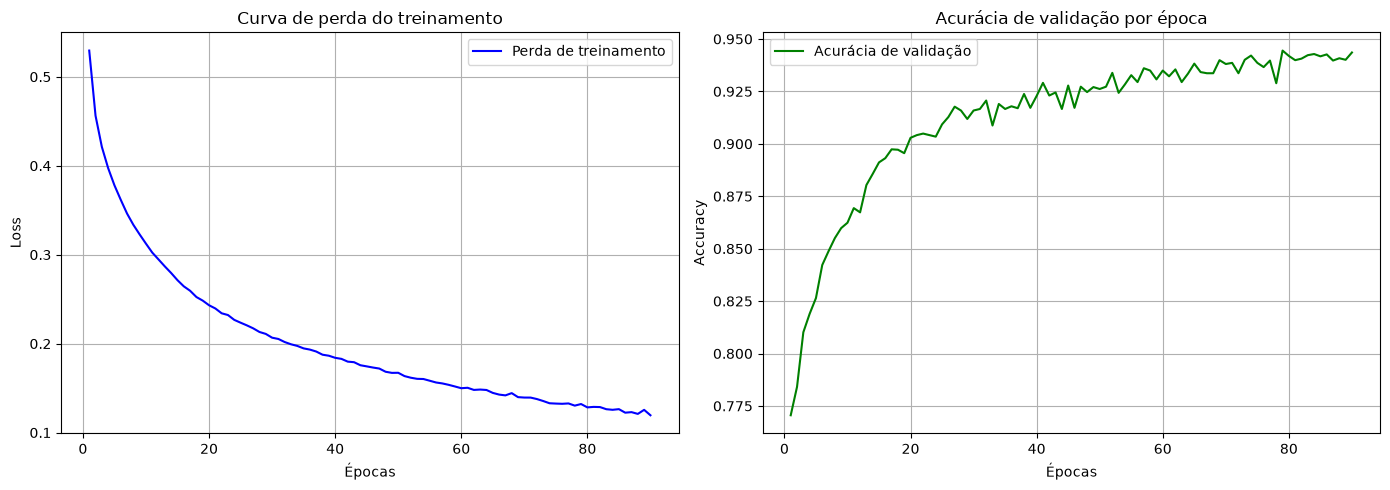

In [7]:
# ============================================================
# 10. DIVISÃO DO TREINO PARA BUSCA DOS PARÂMETROS
# ============================================================

# Como os dados já estão ordenados cronologicamente,
# usamos os primeiros 80% para treinamento e os últimos
# 20% para validação.

split_validacao = int(len(X_train) * 0.80)

X_treino_busca = X_train.iloc[:split_validacao].copy()
y_treino_busca = y_train.iloc[:split_validacao].copy()

X_validacao = X_train.iloc[split_validacao:].copy()
y_validacao = y_train.iloc[split_validacao:].copy()

print("\nDados utilizados na busca:")
print(f"Treinamento: {len(X_treino_busca):,}")
print(f"Validação:   {len(X_validacao):,}")


# ============================================================
# 11. TESTE DE TODAS AS CONFIGURAÇÕES
# ============================================================

resultados = []

total_configuracoes = len(combinacoes)

print("\n" + "=" * 70)
print("INICIANDO BUSCA DE HIPERPARÂMETROS")
print("=" * 70)

print(f"Total de configurações: {total_configuracoes}")

for numero, parametros in enumerate(combinacoes, start=1):

    print(
        f"\n[{numero}/{total_configuracoes}] "
        f"Testando: {parametros}"
    )

    mlp_teste = MLPClassifier(
        **FIXED_PARAMS,
        **parametros
    )


    X_treino_balanceado, y_treino_balanceado = balancear_dados(
    X_treino_busca,
    y_treino_busca,
    BALANCEAMENTO
    )

    mlp_teste.fit(
    X_treino_balanceado,
    y_treino_balanceado
    )


    # ========================================================
    # PREDIÇÃO NA VALIDAÇÃO
    # ========================================================

    y_prob_validacao = mlp_teste.predict_proba(
        X_validacao
    )[:, 1]

    y_pred_validacao = (
        y_prob_validacao >= THRESHOLD
    ).astype(int)

    # ========================================================
    # MÉTRICAS
    # ========================================================

    accuracy = accuracy_score(
        y_validacao,
        y_pred_validacao
    )

    precision = precision_score(
        y_validacao,
        y_pred_validacao,
        pos_label=1,
        zero_division=0
    )

    recall = recall_score(
        y_validacao,
        y_pred_validacao,
        pos_label=1,
        zero_division=0
    )

    f1 = f1_score(
        y_validacao,
        y_pred_validacao,
        pos_label=1,
        zero_division=0
    )

    f2 = fbeta_score(
        y_validacao,
        y_pred_validacao,
        beta=2,
        pos_label=1,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_validacao,
        y_prob_validacao
    )

    precision_pr, recall_pr, _ = precision_recall_curve(
        y_validacao,
        y_prob_validacao,
        pos_label=1
    )

    pr_auc = auc(
        recall_pr,
        precision_pr
    )

    # ========================================================
    # SALVA RESULTADO
    # ========================================================

    resultado = {
        **parametros,

        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "f2": f2,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,

        "epocas_executadas": mlp_teste.n_iter_
    }

    resultados.append(resultado)

    print(
        f"F2: {f2:.4f} | "
        f"Recall: {recall:.4f} | "
        f"Precision: {precision:.4f} | "
        f"PR-AUC: {pr_auc:.4f} | "
        f"Épocas: {mlp_teste.n_iter_}"
    )



# ============================================================
# 11.1 RANKING DAS CONFIGURAÇÕES
# ============================================================

resultados_df = pd.DataFrame(resultados)

PRECISION_MINIMA = 0.10

resultados_filtrados = resultados_df[
    resultados_df["precision"] >= PRECISION_MINIMA
].copy()

if len(resultados_filtrados) == 0:

    print(
        "\nAVISO: Nenhuma configuração atingiu "
        f"Precision >= {PRECISION_MINIMA:.2f}."
    )

    print("\nMelhores resultados por precisão:")
    display(
        resultados_df.sort_values(
            by=["precision", "recall", "pr_auc"],
            ascending=False
        ).head(10)
    )

    print(
        "\nSelecionando a configuração com maior "
        "precision para permitir a análise."
    )

    resultados_filtrados = resultados_df.sort_values(
        by=["precision", "recall", "pr_auc"],
        ascending=False
    ).reset_index(drop=True)

else:

    print(
        f"\nConfigurações com Precision >= "
        f"{PRECISION_MINIMA:.2f}: "
        f"{len(resultados_filtrados)}"
    )

    # Entre as configurações aprovadas, prioriza:
    # 1. Maior Recall
    # 2. Maior F2
    # 3. Maior PR-AUC

    resultados_filtrados = resultados_filtrados.sort_values(
        by=["recall", "f2", "pr_auc"],
        ascending=False
    ).reset_index(drop=True)

melhor_resultado = resultados_filtrados.iloc[0]

print("\n" + "=" * 70)
print("MELHOR CONFIGURAÇÃO SELECIONADA")
print("=" * 70)

display(resultados_filtrados.head(10))

print(f"Precision: {melhor_resultado['precision']:.4f}")
print(f"Recall:    {melhor_resultado['recall']:.4f}")
print(f"F2:        {melhor_resultado['f2']:.4f}")
print(f"PR-AUC:    {melhor_resultado['pr_auc']:.4f}")


# ============================================================
# 11.2 MELHOR CONFIGURAÇÃO
# ============================================================

# Usa a melhor configuração entre as que passaram no critério de precisão.
# Não usar resultados_df.iloc[0]: ele apenas pega a primeira combinação testada.
melhor_resultado = resultados_filtrados.iloc[0]

BEST_PARAMS = {
    "hidden_layer_sizes": melhor_resultado["hidden_layer_sizes"],
    "learning_rate_init": melhor_resultado["learning_rate_init"],
    "batch_size": int(melhor_resultado["batch_size"]),
    "alpha": melhor_resultado["alpha"],
    "max_iter": int(melhor_resultado["max_iter"])
}

MLP_PARAMS = {
    **FIXED_PARAMS,
    **BEST_PARAMS
}

print("\n" + "=" * 70)
print("MELHOR CONFIGURAÇÃO ENCONTRADA")
print("=" * 70)

print(f"Arquitetura:       {BEST_PARAMS['hidden_layer_sizes']}")
print(f"Learning rate:     {BEST_PARAMS['learning_rate_init']}")
print(f"Batch size:        {BEST_PARAMS['batch_size']}")
print(f"Alpha:             {BEST_PARAMS['alpha']}")
print(f"Max iter:          {BEST_PARAMS['max_iter']}")

print("\nParâmetros fixos:")
print(f"Activation:        {FIXED_PARAMS['activation']}")
print(f"Solver:            {FIXED_PARAMS['solver']}")

print("\nResultado na validação:")
print(f"Accuracy:           {melhor_resultado['accuracy']:.4f}")
print(f"Precision:          {melhor_resultado['precision']:.4f}")
print(f"Recall:             {melhor_resultado['recall']:.4f}")
print(f"F1:                 {melhor_resultado['f1']:.4f}")
print(f"F2:                 {melhor_resultado['f2']:.4f}")
print(f"ROC-AUC:            {melhor_resultado['roc_auc']:.4f}")
print(f"PR-AUC:             {melhor_resultado['pr_auc']:.4f}")


# ============================================================
# 11.3 TREINAMENTO FINAL COM A MELHOR CONFIGURAÇÃO
# ============================================================

print("\n" + "=" * 70)
print("TREINAMENTO FINAL")
print("=" * 70)

mlp = MLPClassifier(
    **MLP_PARAMS
)


X_train_balanceado, y_train_balanceado = balancear_dados(
    X_train,
    y_train,
    BALANCEAMENTO
)

print("\nDistribuição original do treino:")
print(y_train.value_counts().sort_index())

print("\nDistribuição balanceada do treino:")
print(y_train_balanceado.value_counts().sort_index())

mlp.fit(
    X_train_balanceado,
    y_train_balanceado
)


print(
    f"Épocas executadas no modelo final: {mlp.n_iter_}"
)


# ============================================================
# 11.4 SALVAMENTO DO MODELO FINAL
# ============================================================

# O modelo recebe 26 variáveis numéricas, mas a API recebe os campos brutos
# do formulário/CSV. Por isso, o artefato precisa carregar também os mapas
# de target encoding criados SOMENTE com o conjunto de treino.

raw_columns = [
    "purchase_date",
    "purchase_time",
    "carrier_datetime",
    "estimated_delivery_datetime",
    "price",
    "freight_value",
    "product_weight_g",
    "height_cm",
    "width_cm",
    "length_cm",
    "distance_km",
    "same_city"
]

modelo = {
    # Objetos necessários para a inferência
    "model": mlp,
    "scaler": scaler,
    "features": X_train.columns.tolist(),
    "feature_names": X_train.columns.tolist(),
    "threshold": float(THRESHOLD),
    "params": MLP_PARAMS,

    # Dados necessários para repetir o pré-processamento da API
    "raw_columns": raw_columns,
    "inference_moment": "carrier_collection",
    "ecommerce_events": [
        "mothers_day", "fathers_day", "children_day",
        "black_friday", "cyber_monday", "christmas",
    ],

    # Contrato do artefato consumido pela API
    "schema_version": 3,
    "model_type": "MLPClassifier",
    "model_name": "MLP (Rede Neural)",
}


caminho_modelo = Path.cwd() / (
    f"modelo_mlp_{BALANCEAMENTO}.pkl"
)


with open(
    caminho_modelo,
    "wb"
) as arquivo:

    pickle.dump(
        modelo,
        arquivo,
        protocol=pickle.HIGHEST_PROTOCOL
    )

print(
    f"\nModelo final salvo com sucesso em: "
    f"{caminho_modelo}"
)
print(f"Variáveis do modelo: {len(modelo['features'])}")
print(f"Limiar de atraso: {modelo['threshold']:.2f}")


# ============================================================
# 11.2 GRÁFICOS DE TREINAMENTO E VALIDAÇÃO
# ============================================================

epocas = range(1, len(mlp.loss_curve_) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1 - Perda do treinamento
axes[0].plot(
    epocas,
    mlp.loss_curve_,
    label="Perda de treinamento",
    color="blue"
)

axes[0].set_title("Curva de perda do treinamento")
axes[0].set_xlabel("Épocas")
axes[0].set_ylabel("Loss")
axes[0].grid(True)
axes[0].legend()

# Gráfico 2 - Acurácia de validação
if mlp.validation_scores_ is not None:
    epocas_validacao = range(
        1,
        len(mlp.validation_scores_) + 1
    )

    axes[1].plot(
        epocas_validacao,
        mlp.validation_scores_,
        label="Acurácia de validação",
        color="green"
    )

    axes[1].set_title("Acurácia de validação por época")
    axes[1].set_xlabel("Épocas")
    axes[1].set_ylabel("Accuracy")
    axes[1].grid(True)
    axes[1].legend()

plt.tight_layout()
plt.show()

# Gráfico 01
A curva de perda mostra o erro que o modelo apresenta durante o treinamento.

Curva decrescente: o modelo está aprendendo a ajustar seus pesos.

Curva estabilizada: o treinamento pode ter atingido um platô.

Curva crescente: pode indicar instabilidade ou dificuldades de otimização.

# Gráfico 02

A curva de validação mostra como o modelo classifica as amostras reservadas para validação durante o treinamento.

Acurácia crescente: o modelo está melhorando sua capacidade de classificação no conjunto de validação.

Acurácia estabilizada: pode indicar que o modelo deixou de apresentar melhorias.

Acurácia decrescente: pode indicar que o modelo está perdendo capacidade de generalização.

In [8]:
# ============================================================
# 12. PREDIÇÃO
# ============================================================

y_prob = mlp.predict_proba(
    X_test
)[:, 1]

y_pred = (
    y_prob >= THRESHOLD
).astype(int)

In [9]:
# ============================================================
# 13. MÉTRICAS
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision_atraso = precision_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

recall_atraso = recall_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

f1_atraso = f1_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

f2_atraso = fbeta_score(
    y_test,
    y_pred,
    beta=2,
    pos_label=1,
    zero_division=0
)

roc_auc_atraso = roc_auc_score(
    y_test,
    y_prob
)

precision_pr, recall_pr, _ = precision_recall_curve(
    y_test,
    y_prob,
    pos_label=1
)

pr_auc_atraso = auc(
    recall_pr,
    precision_pr
)


RESULTADOS - MLP
Arquitetura: (64, 32)
Activation: relu
Solver: adam
Learning rate: 0.001
Batch size: 128
Épocas máximas: 100
Limiar: 0.25

Quantidade de amostras:
Treino: 28603
Teste:  5000

Métricas:
Accuracy:        0.6894
Precision atraso: 0.1985
Recall atraso:    0.6954
F1 atraso:        0.3089
F2 atraso:        0.4634
ROC-AUC atraso:   0.7645
PR-AUC atraso:    0.2375

Como interpretar as métricas:
- Precision atraso: entre os pedidos previstos como atraso, quantos realmente atrasaram.
- Recall atraso: entre os pedidos que realmente atrasaram, quantos o modelo conseguiu detectar.
- F1 atraso: média harmônica entre precision e recall.
- F2 atraso: semelhante ao F1, mas dando mais peso ao recall.
- ROC-AUC atraso: capacidade do modelo de separar atrasos de não atrasos em diferentes limiares.
- PR-AUC atraso: desempenho no equilíbrio entre precision e recall para a classe atraso.


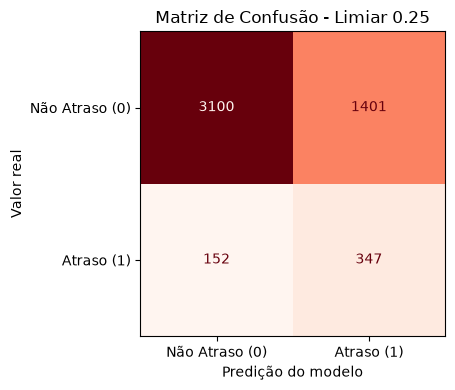


Relatório de classificação:
                precision    recall  f1-score   support

Não Atraso (0)       0.95      0.69      0.80      4501
    Atraso (1)       0.20      0.70      0.31       499

      accuracy                           0.69      5000
     macro avg       0.58      0.69      0.55      5000
  weighted avg       0.88      0.69      0.75      5000


Quantidade de épocas executadas:
90


In [10]:
# ============================================================
# 14. RESULTADOS
# ============================================================

print("\n" + "=" * 60)
print("RESULTADOS - MLP")
print("=" * 60)

print(f"Arquitetura: {MLP_PARAMS['hidden_layer_sizes']}")
print(f"Activation: {MLP_PARAMS['activation']}")
print(f"Solver: {MLP_PARAMS['solver']}")
print(f"Learning rate: {MLP_PARAMS['learning_rate_init']}")
print(f"Batch size: {MLP_PARAMS['batch_size']}")
print(f"Épocas máximas: {MLP_PARAMS['max_iter']}")
print(f"Limiar: {THRESHOLD:.2f}")

print("\nQuantidade de amostras:")
print(f"Treino: {len(X_train)}")
print(f"Teste:  {len(X_test)}")

print("\nMétricas:")
print(f"Accuracy:        {accuracy:.4f}")
print(f"Precision atraso: {precision_atraso:.4f}")
print(f"Recall atraso:    {recall_atraso:.4f}")
print(f"F1 atraso:        {f1_atraso:.4f}")
print(f"F2 atraso:        {f2_atraso:.4f}")
print(f"ROC-AUC atraso:   {roc_auc_atraso:.4f}")
print(f"PR-AUC atraso:    {pr_auc_atraso:.4f}")

# ============================================================
# INTERPRETAÇÃO DAS MÉTRICAS
# ============================================================

print("\nComo interpretar as métricas:")
print("- Precision atraso: entre os pedidos previstos como atraso, quantos realmente atrasaram.")
print("- Recall atraso: entre os pedidos que realmente atrasaram, quantos o modelo conseguiu detectar.")
print("- F1 atraso: média harmônica entre precision e recall.")
print("- F2 atraso: semelhante ao F1, mas dando mais peso ao recall.")
print("- ROC-AUC atraso: capacidade do modelo de separar atrasos de não atrasos em diferentes limiares.")
print("- PR-AUC atraso: desempenho no equilíbrio entre precision e recall para a classe atraso.")

# ============================================================
# MATRIZ DE CONFUSÃO
# ============================================================

fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Reds",
    ax=ax,
    colorbar=False,
    display_labels=[
        "Não Atraso (0)",
        "Atraso (1)"
    ]
)

ax.set_title(
    f"Matriz de Confusão - Limiar {THRESHOLD:.2f}"
)

ax.set_xlabel("Predição do modelo")
ax.set_ylabel("Valor real")

plt.tight_layout()
plt.show()

# ============================================================
# RELATÓRIO DE CLASSIFICAÇÃO
# ============================================================

print("\nRelatório de classificação:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Não Atraso (0)",
            "Atraso (1)"
        ],
        zero_division=0
    )
)

print("\nQuantidade de épocas executadas:")
print(mlp.n_iter_)